# 08. 모델 성능·이벤트 경보·신뢰성 비교

모든 수치는 실제 저장된 예측 점수와 고정된 검증 임계값에서 계산했습니다. 모델 구성의 대표 비교는 **각 RF/XGBoost 계열 내 검증 AP 최대**를 사용합니다. 평가 점수가 가장 높은 구성을 사후 선정하지 않습니다. 별도 정답 미확인 구간 추론은 RF/XGBoost A/B/C 6개 중 검증 AP 최대 모델을 사용했습니다.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd() if (Path.cwd()/"src").is_dir() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
assert Path(sys.prefix).name.lower()=="phm2018"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.model_common import OUT,configs,read_json
from src.model_summary import collect,selected_per_family
from src import model_plots as plots
plots.setup()
objects,metrics=collect()
audit=read_json(OUT/"preflight.json")
pd.set_option("display.max_columns",40)
print("실행 환경:",sys.executable)
print("실제 학습 완료 모델을 읽음. 기존 점수와 임계값을 재사용하며 평가 세트로 재조정하지 않음.")

실행 환경: C:\Users\fl27\anaconda3\envs\phm2018\python.exe
실제 학습 완료 모델을 읽음. 기존 점수와 임계값을 재사용하며 평가 세트로 재조정하지 않음.


## 샘플 지표와 곡선

Precision, Recall, F1, PR-AUC(AP), ROC-AUC, 혼동행렬을 제공합니다. 주 곡선은 정답이 확인된 평가 행에 한정됩니다. 전체 현장의 무편향 성능이 아닙니다. 아래 그래프는 600 구간이며 확장 수치는 별도 표에 있습니다.

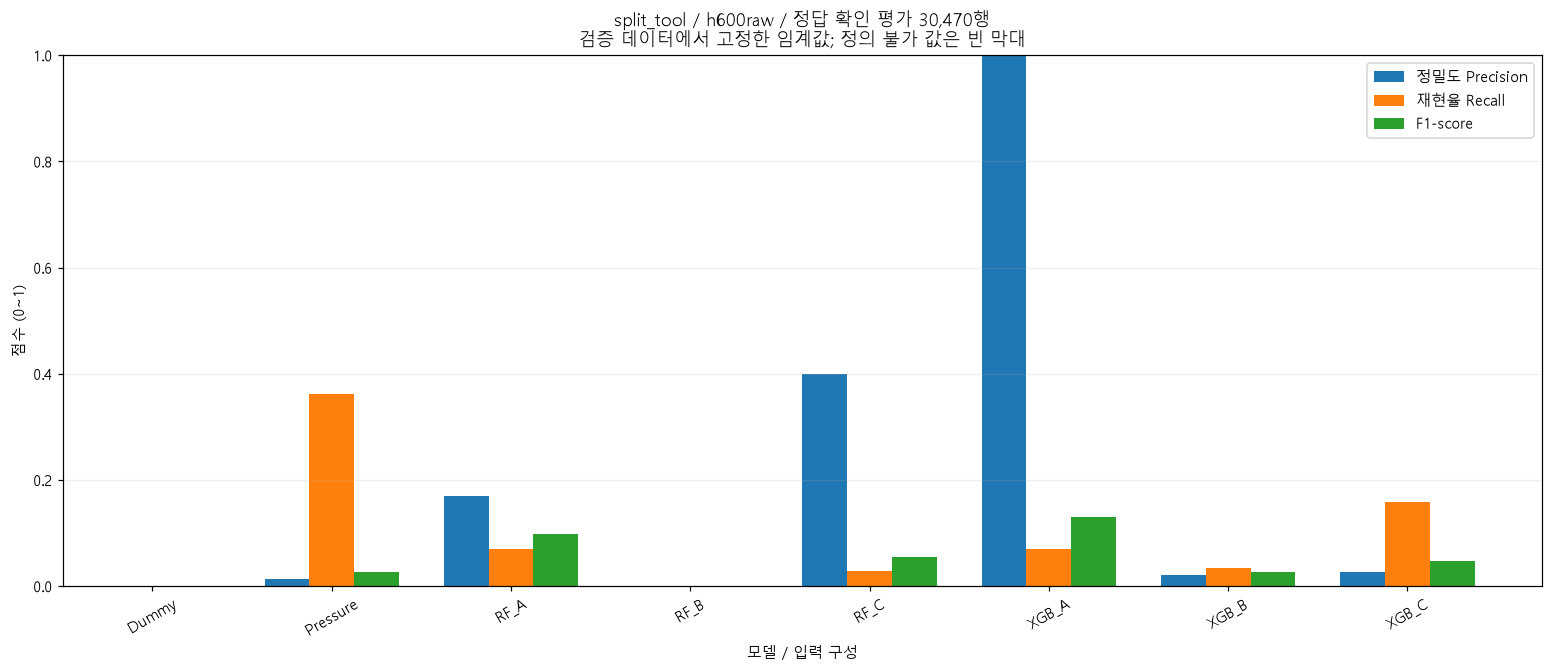

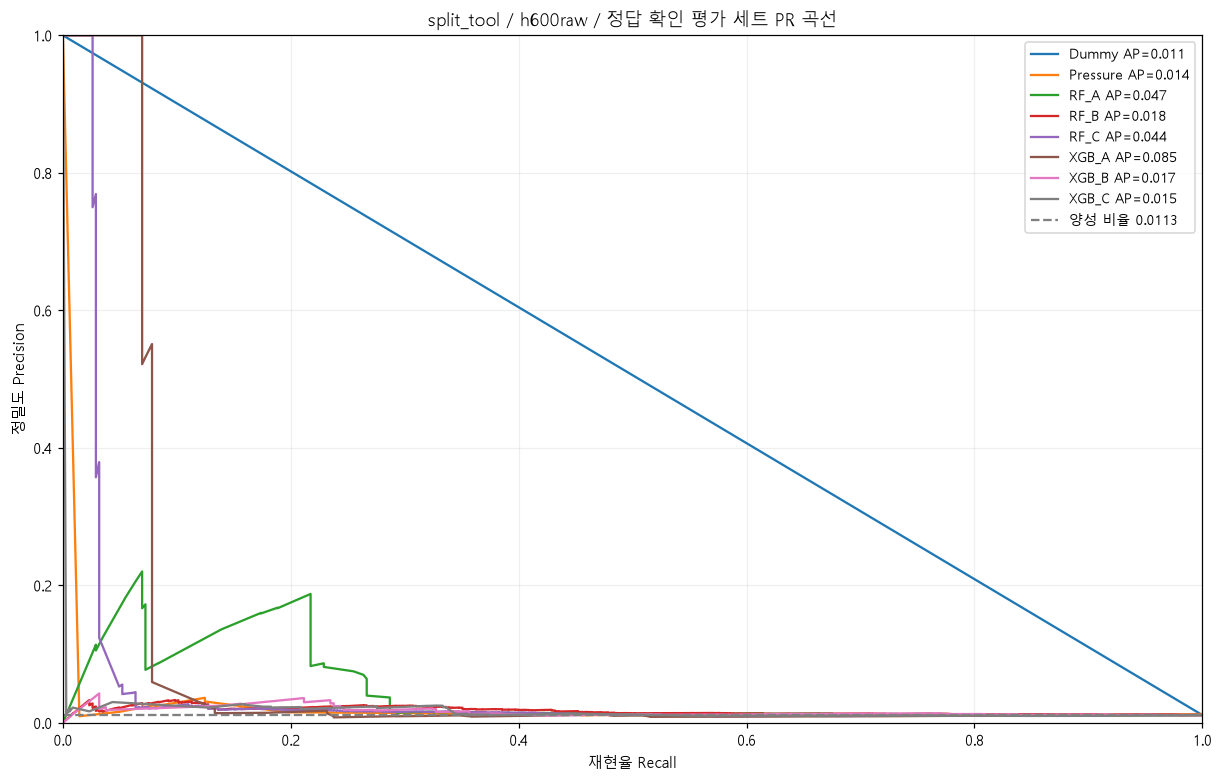

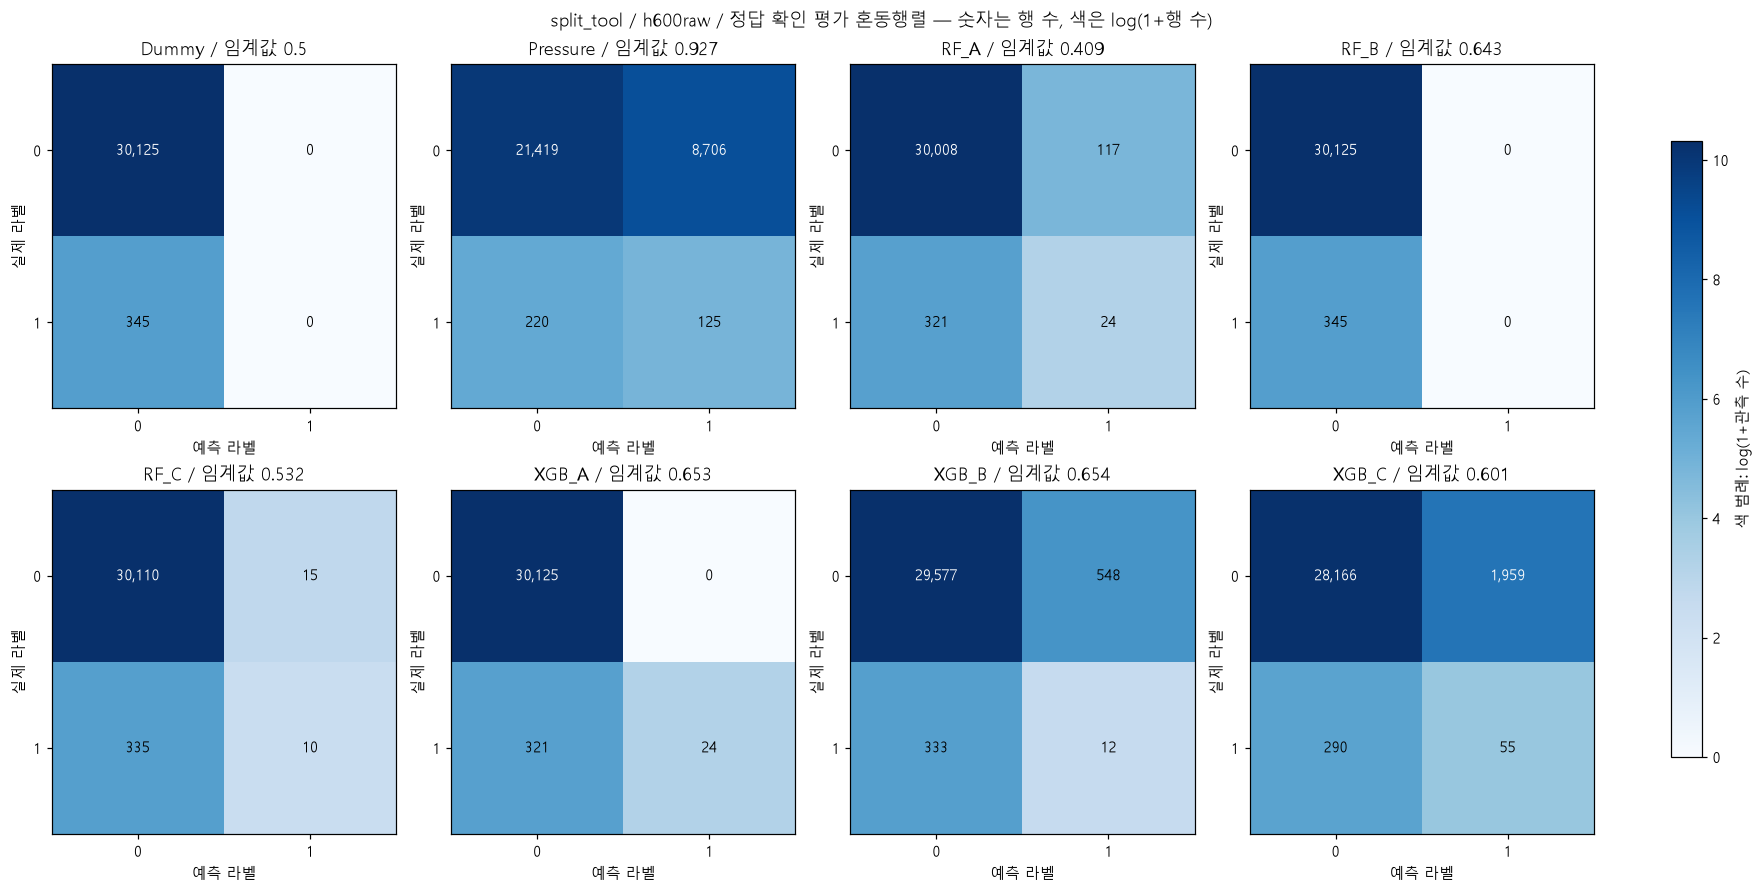

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


... (6 outputs left out)

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


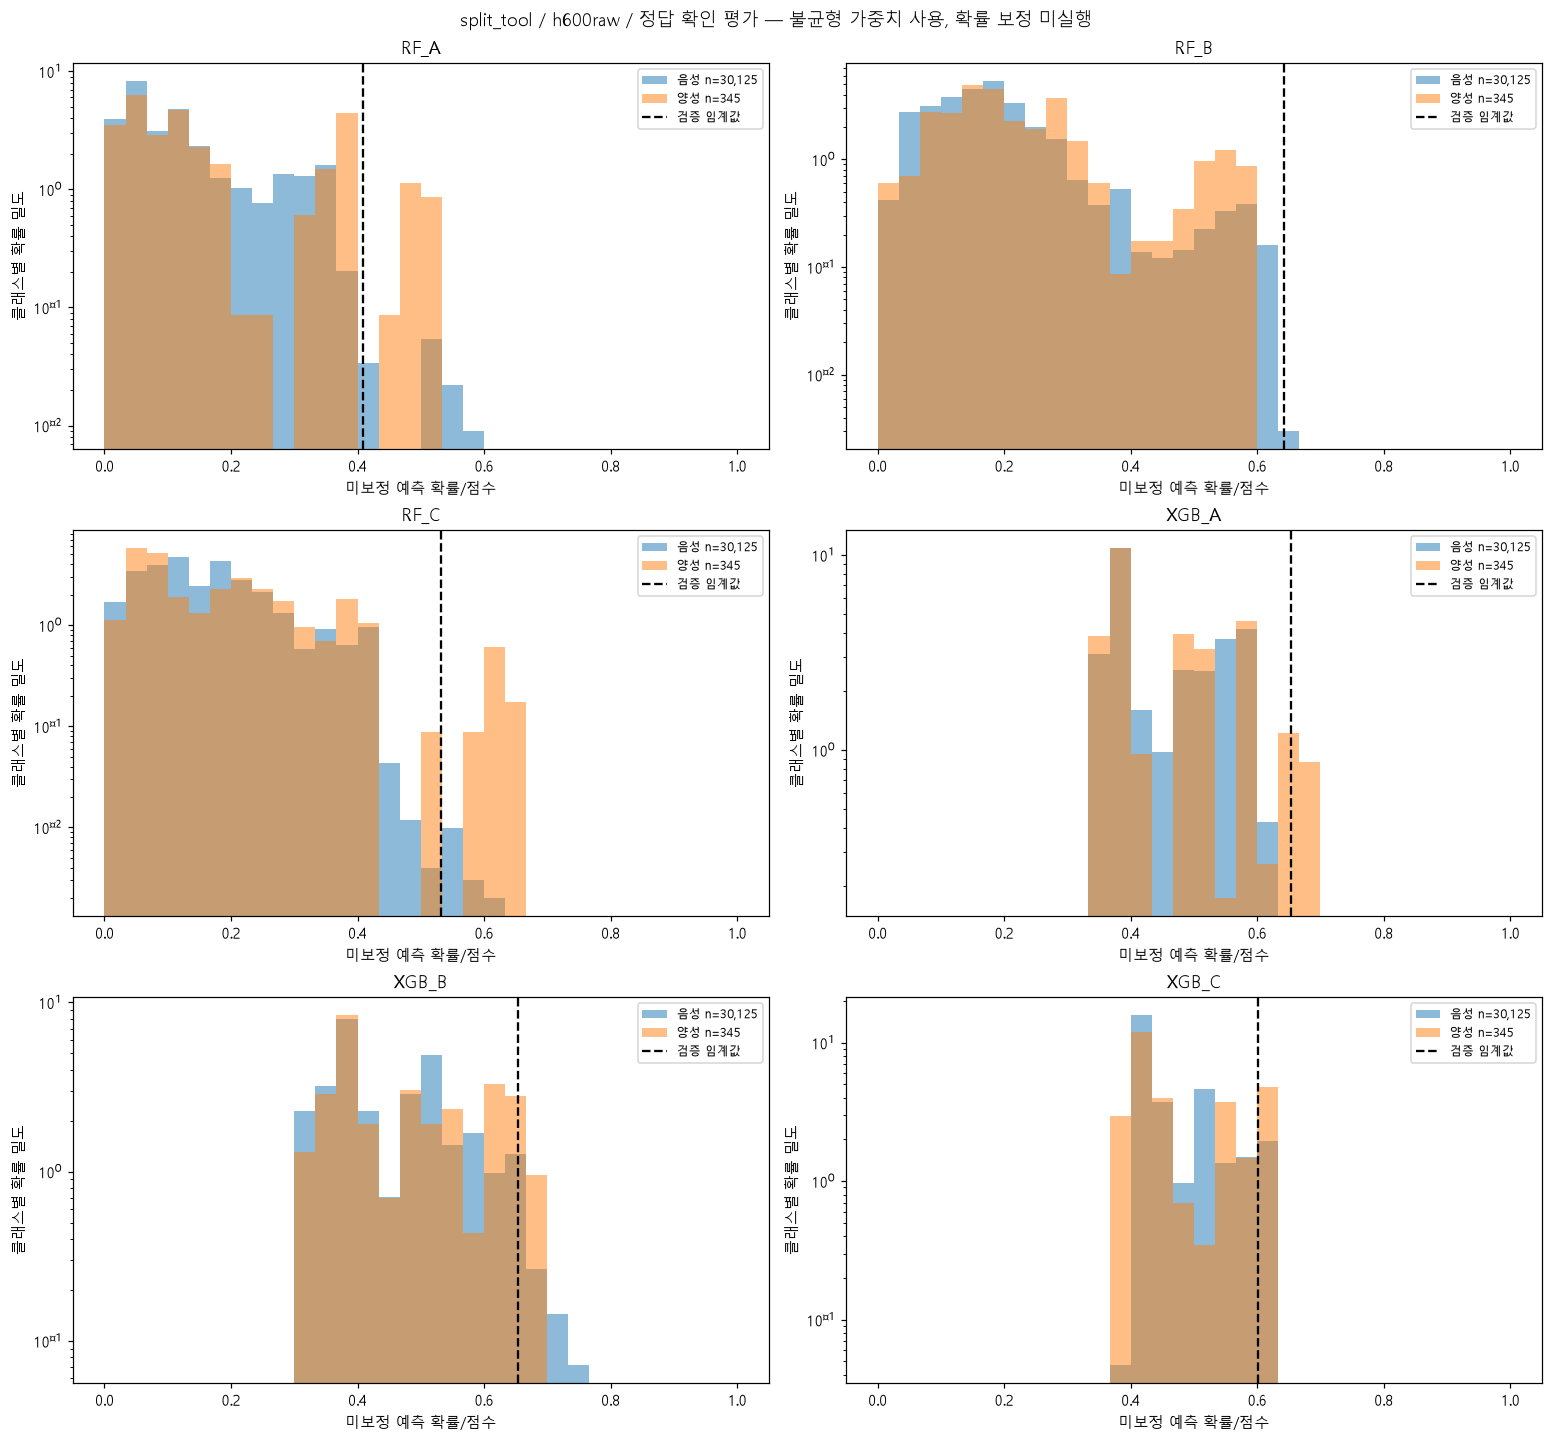

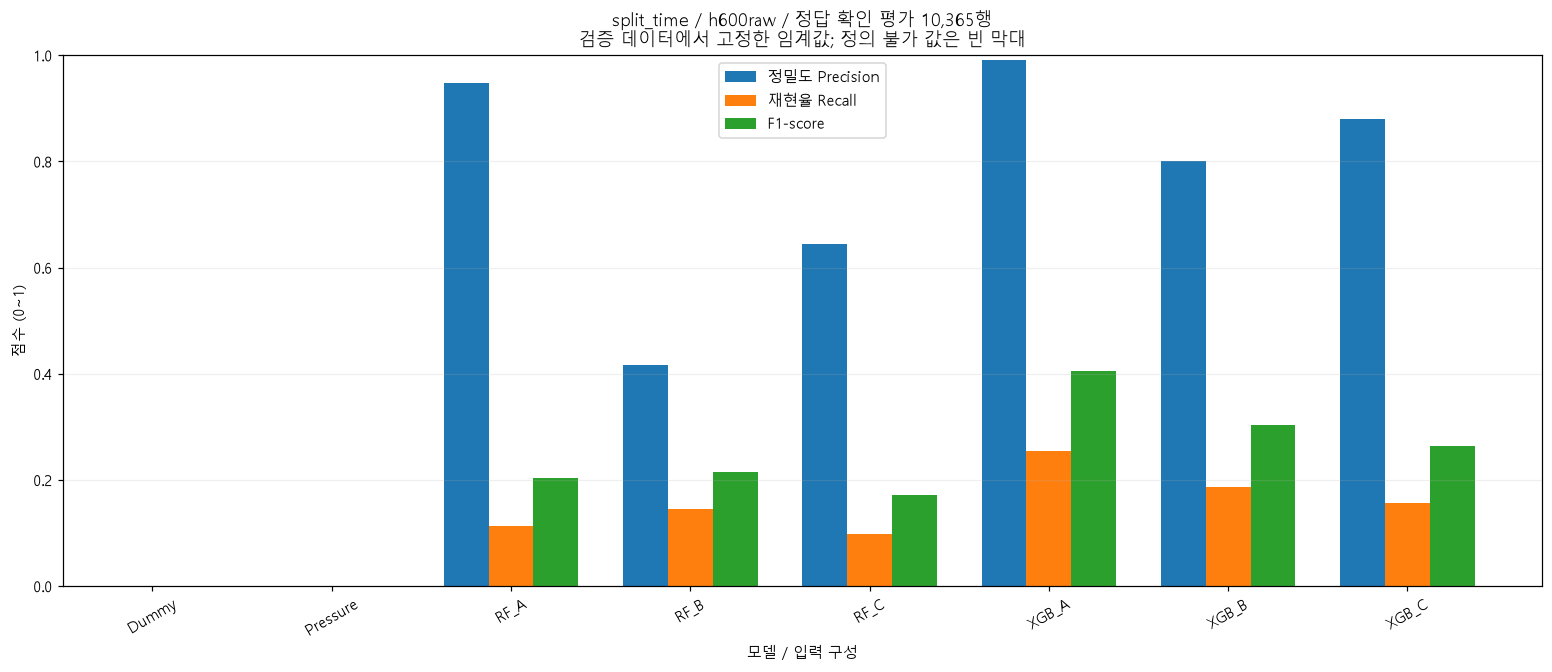

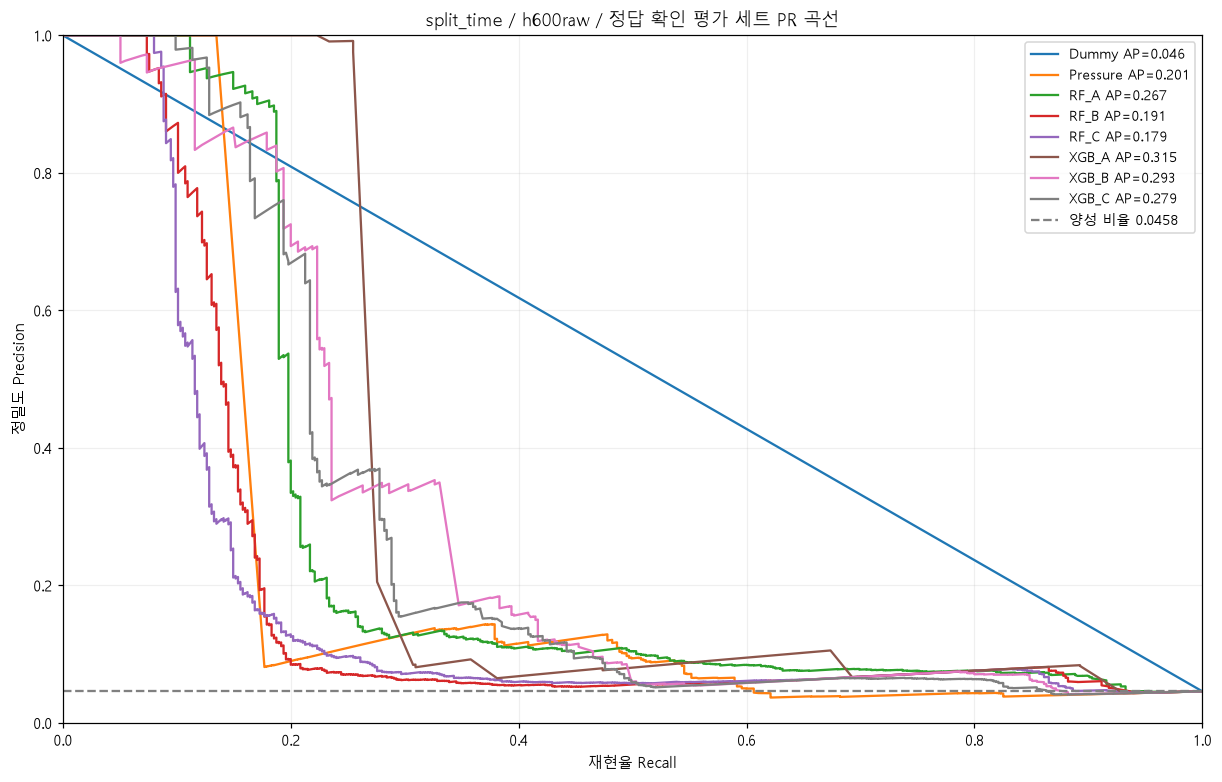

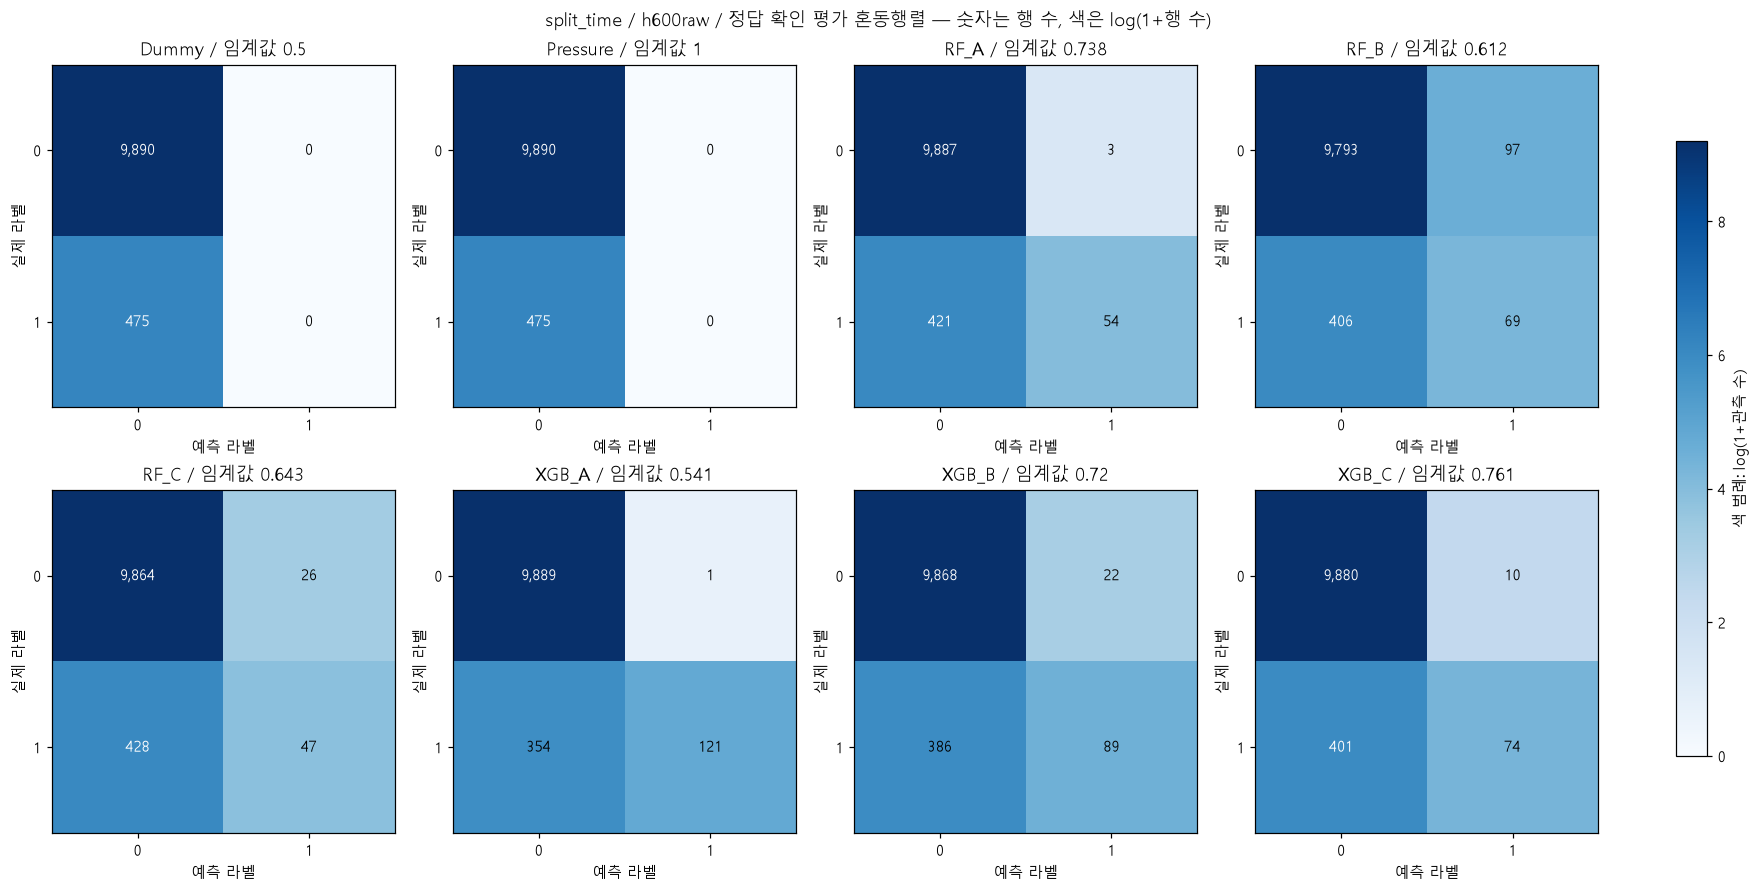

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


... (6 outputs left out)

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


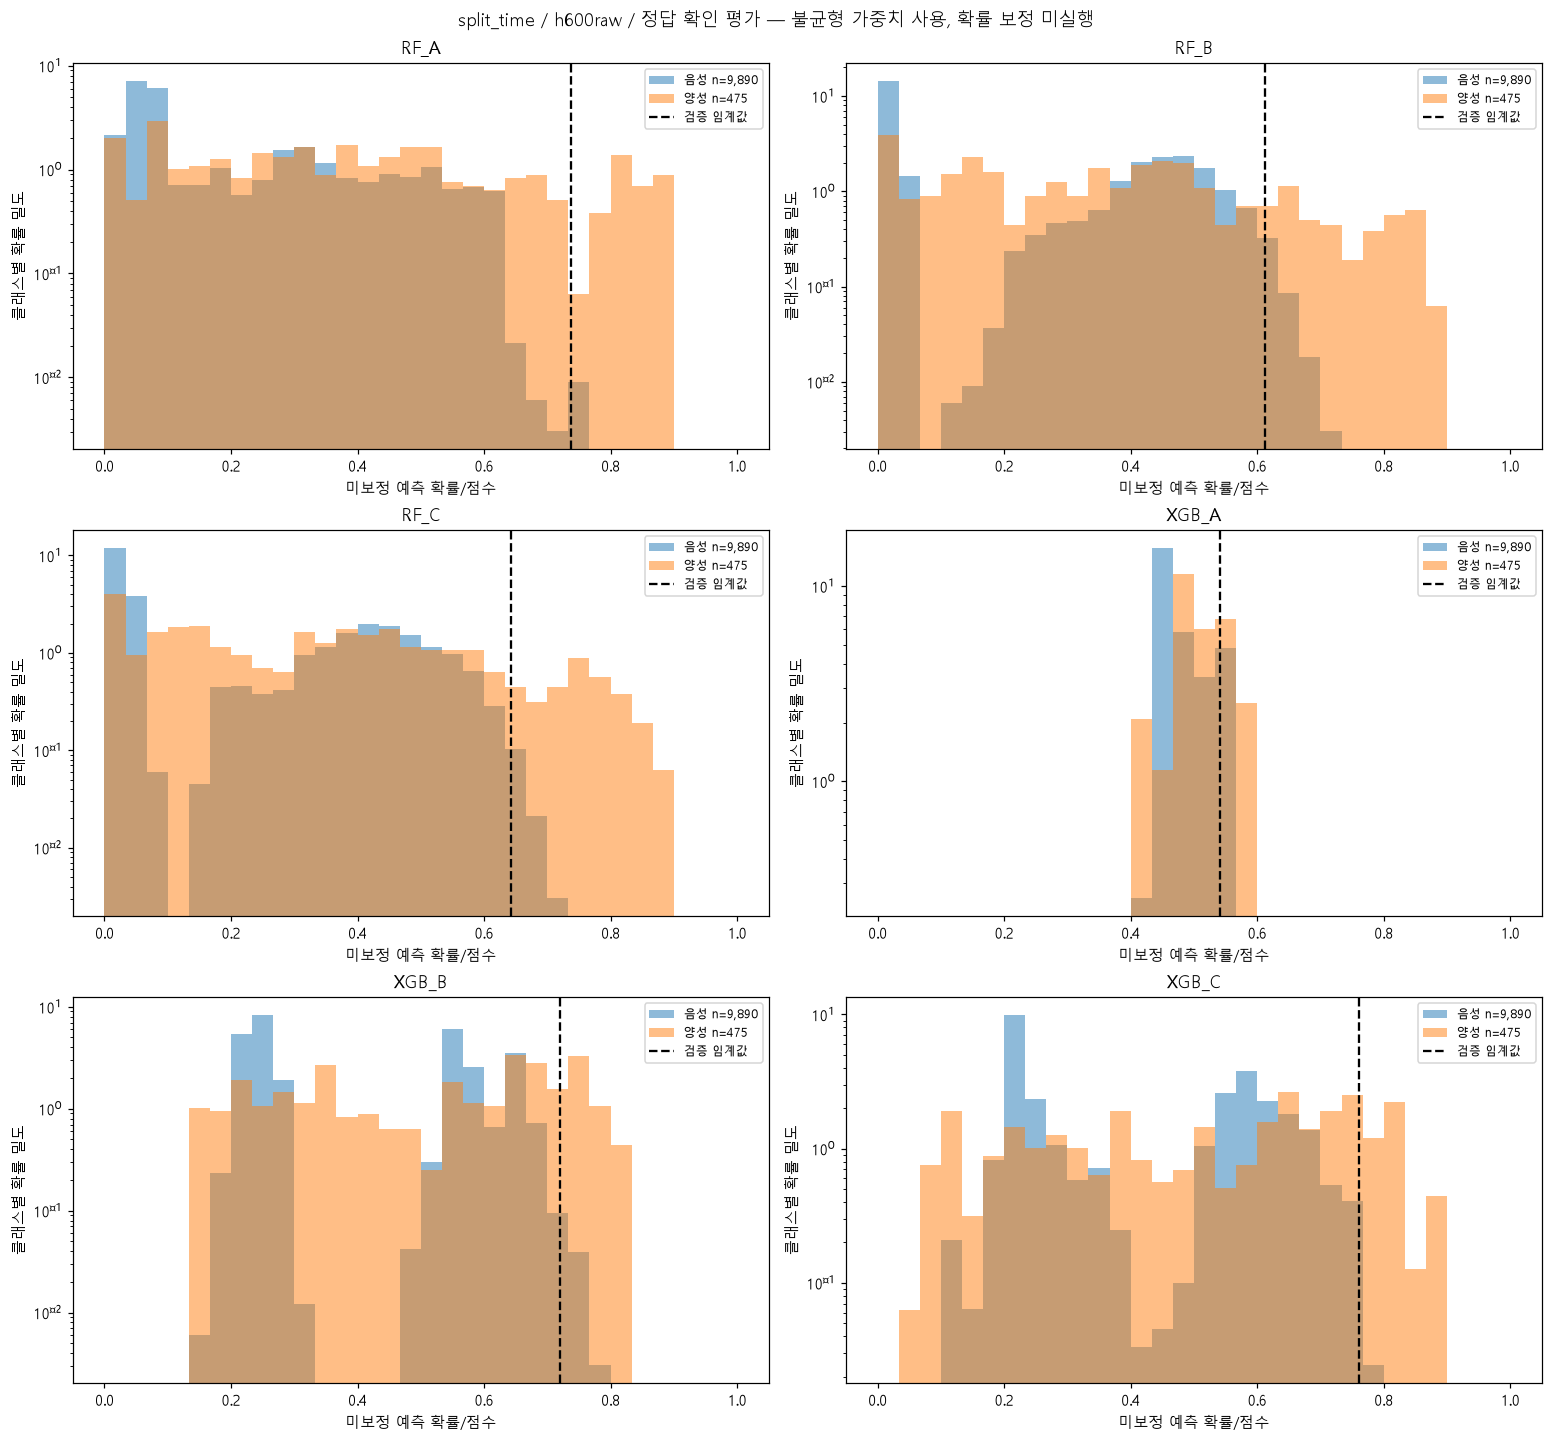

,분할,검증 선정 모델,Precision,Recall,F1,AP,ROC-AUC
0,split_tool,RF_A,0.170213,0.069565,0.098765,0.047113,0.583816
1,split_tool,XGB_A,1.000000,0.069565,0.130081,0.085175,0.457383
2,split_time,RF_B,0.415663,0.145263,0.215289,0.191183,0.636709
3,split_time,XGB_C,0.880952,0.155789,0.264758,0.278805,0.643686


In [2]:
for scheme in ("split_tool","split_time"):
    plots.comparison(scheme);plots.pr_curves(scheme);plots.confusion(scheme);plots.score_histograms(scheme)
selected=selected_per_family(objects)
display(pd.DataFrame([{ "분할":r["scheme"],"검증 선정 모델":r["name"],"Precision":r["metrics"]["evaluation"]["precision"],"Recall":r["metrics"]["evaluation"]["recall"],"F1":r["metrics"]["evaluation"]["f1"],"AP":r["metrics"]["evaluation"]["pr_auc_ap"],"ROC-AUC":r["metrics"]["evaluation"]["roc_auc"]} for r in selected]))

## 이벤트·경보·노출시간 정의

이벤트 키는 Tool·고장 시각·유형입니다. 평가 가능한 이벤트는 자기 next_event 키와 일치하는 양성 anchor가 있는 경우입니다. 경보는 같은 Tool·관측 세그먼트·Stage=0/>0 상태에서 연속 양성인 점들을 병합합니다. 음성, 72 초과 간격, 상태 변경에서 끊고 H마다 재발행합니다.

한 경보는 H 이내의 가장 이른 미래 이벤트 시각에만 대응합니다. 동시각의 여러 유형은 함께 기록할 수 있으며, 한 이벤트의 여러 경보는 탐지 한 번으로 셉니다. Lead Time은 매칭된 실제 경보 시각에서 이벤트까지의 차이이며 탐지된 이벤트에만 정의됩니다.

오경보는 관련 이벤트에 매칭되지 않고 에피소드 전체가 확인된 음성일 때만 셉니다. NA를 포함하면 미확인 경보로 남깁니다. 노출시간은 같은 세그먼트의 인접 확인 음성 anchor 사이에서 간격 72 이하인 실제 시간만 합칩니다. 가동 시간당 비율은 Stage>0인 두 끝점으로 제한한 노출을 분모로 합니다. 초 해석에 따라 3600 원시단위를 시간으로 환산합니다. 전체 운전 노출이 아니므로 현장 전체 FAR로 일반화하지 않습니다.

In [3]:
display(pd.DataFrame([{ "분할":r["scheme"],"모델":r["name"],"평가 가능 이벤트":r["metrics"]["evaluation"]["evaluable_events"],"탐지 이벤트":r["metrics"]["evaluation"]["detected_events"],"Event Recall":r["metrics"]["evaluation"]["event_recall"],"가동시간당 오경보":r["metrics"]["evaluation"]["false_alarms_per_active_hour_seconds_interpretation"],"Lead Time 중앙값 raw":r["metrics"]["evaluation"]["lead_time_median_raw"]} for r in selected]))
for r in selected:
    display(Markdown(f"**{r['scheme']} / {r['name']} 유형별 이벤트**"))
    display(pd.DataFrame(r["metrics"]["evaluation"]["per_type"]).T)
display(Markdown("장비 평가의 누출 4건 같은 작은 분모에서 수치가 크게 변할 수 있습니다. 양성 이벤트가 없으면 Recall·Lead Time을 임의 생성하지 않습니다. 한두 이벤트의 성패로 안정적 성능을 주장하지 않습니다."))

,분할,모델,평가 가능 이벤트,탐지 이벤트,Event Recall,가동시간당 오경보,Lead Time 중앙값 raw
0,split_tool,RF_A,45,4,0.088889,0.044882,344.0
1,split_tool,XGB_A,45,4,0.088889,0.000000,344.0
2,split_time,RF_B,56,10,0.178571,0.580220,552.0
3,split_time,XGB_C,56,17,0.303571,0.052747,298.0


**split_tool / RF_A 유형별 이벤트**

,events,detected,recall
f1,30.0,0.0,0.000000
f2,11.0,4.0,0.363636
f3,4.0,0.0,0.000000


**split_tool / XGB_A 유형별 이벤트**

,events,detected,recall
f1,30.0,0.0,0.000000
f2,11.0,4.0,0.363636
f3,4.0,0.0,0.000000


**split_time / RF_B 유형별 이벤트**

,events,detected,recall
f1,35.0,3.0,0.085714
f2,12.0,3.0,0.250000
f3,9.0,4.0,0.444444


**split_time / XGB_C 유형별 이벤트**

,events,detected,recall
f1,35.0,10.0,0.285714
f2,12.0,3.0,0.250000
f3,9.0,4.0,0.444444


장비 평가의 누출 4건 같은 작은 분모에서 수치가 크게 변할 수 있습니다. 양성 이벤트가 없으면 Recall·Lead Time을 임의 생성하지 않습니다. 한두 이벤트의 성패로 안정적 성능을 주장하지 않습니다.

## 정답 미확인 구간을 포함한 전향적 추론

학습 후보 선정의 미래 정답 조건이 현장 성능을 가리지 않도록, 평가 분할의 모든 feature_ready 행에도 고정 모델을 적용했습니다. 이때 NA는 예측은 하되 정상으로 바꾸지 않습니다. 확인 가능한 이벤트 Recall과 전체 기록 대비 도달률을 구분하고, 미확인 경보 수를 함께 제공합니다.

,분할,RF/XGB 검증 선정,evaluable_events,detected_events,event_recall,recorded_events,recorded_events_hit,recorded_recall_with_observation_limit,event_coverage,alarm_episodes,false_alarm_episodes,unknown_alarm_episodes,negative_exposure_raw,false_alarms_per_3600raw,false_alarm_time_fraction,active_negative_exposure_raw,active_false_alarm_episodes,false_alarms_per_active_hour_seconds_interpretation,lead_time_median_raw,lead_time_min_raw,lead_time_max_raw,all_feature_ready_rows,unknown_label_rows,unknown_row_alarm_fraction
0,split_tool,RF_A,45,4,0.088889,244,8,0.032787,0.184426,23770,17,23747,1738814.0,0.035196,0.004279,1363578.0,17,0.044882,344.0,36.0,566.0,335124,304654,0.260860
1,split_time,XGB_C,56,17,0.303571,194,26,0.134021,0.288660,31472,8,31440,546000.0,0.052747,0.001978,546000.0,8,0.052747,298.0,2.0,580.0,442840,432475,0.128162


정답 미확인 구간에서 나온 경보는 확인된 오경보율의 분자에 넣을 수 없습니다. 다수의 미확인 경보가 존재하므로 현재 낮아 보이는 조건부 FAR만으로 현장 도입을 판단할 수 없습니다. 전체 이력 대비 도달률에는 관측/이력 부족도 반영됩니다.

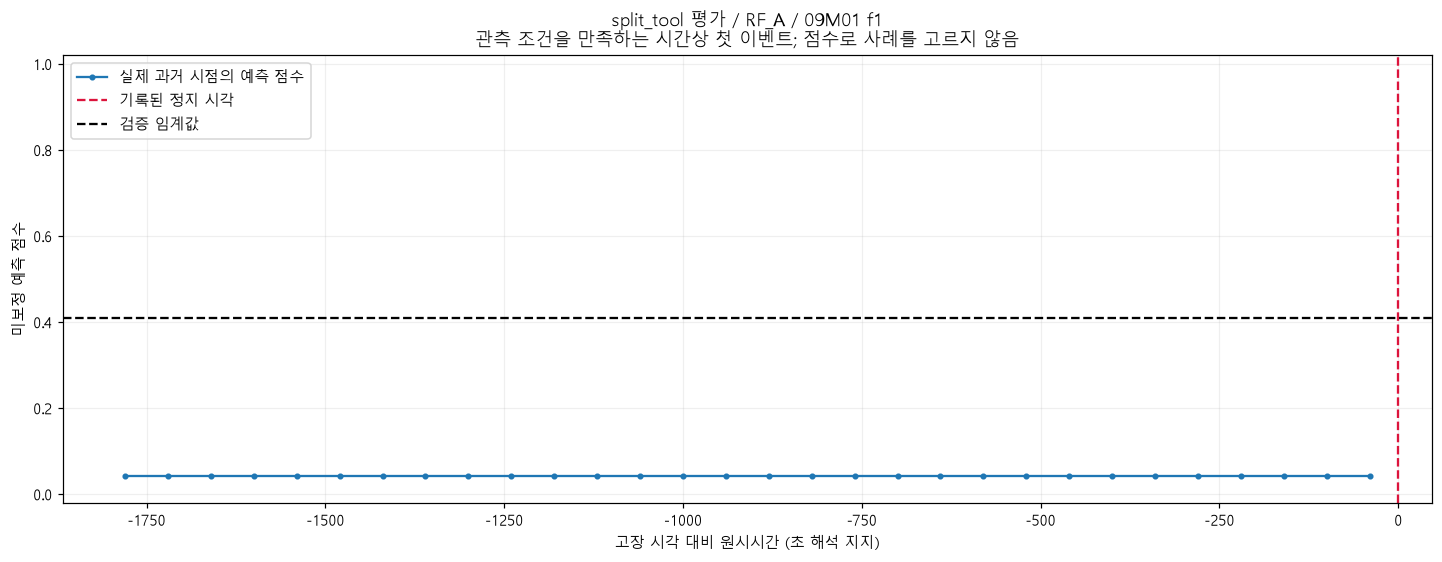

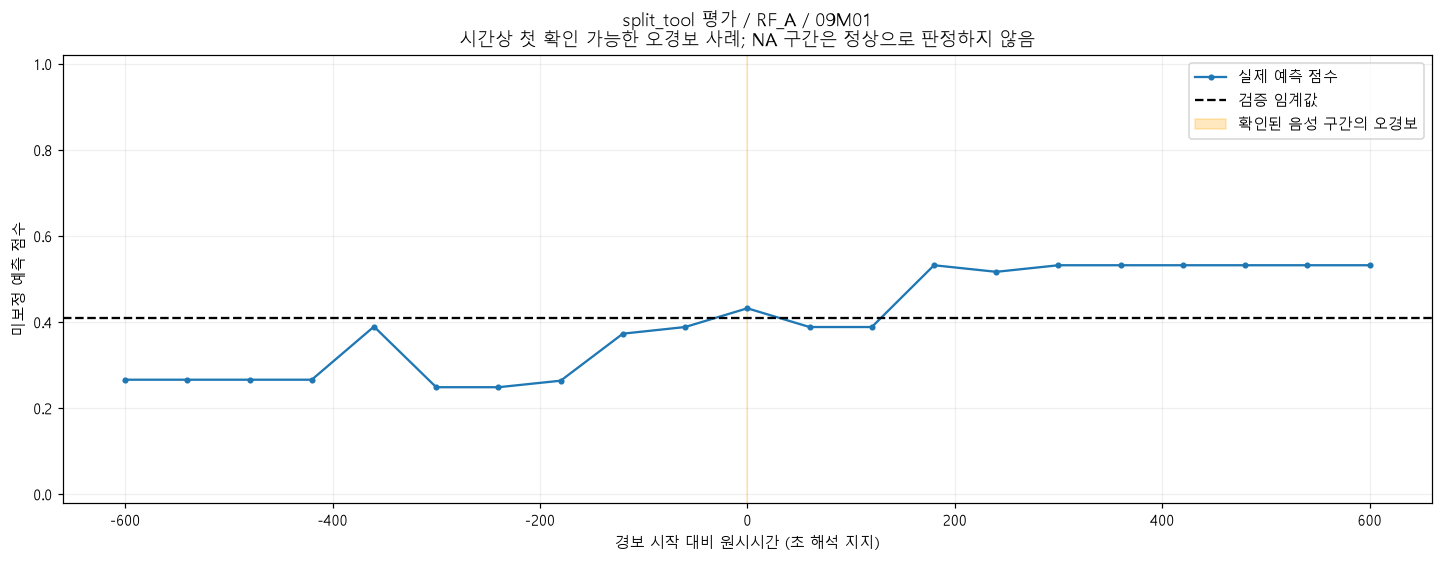

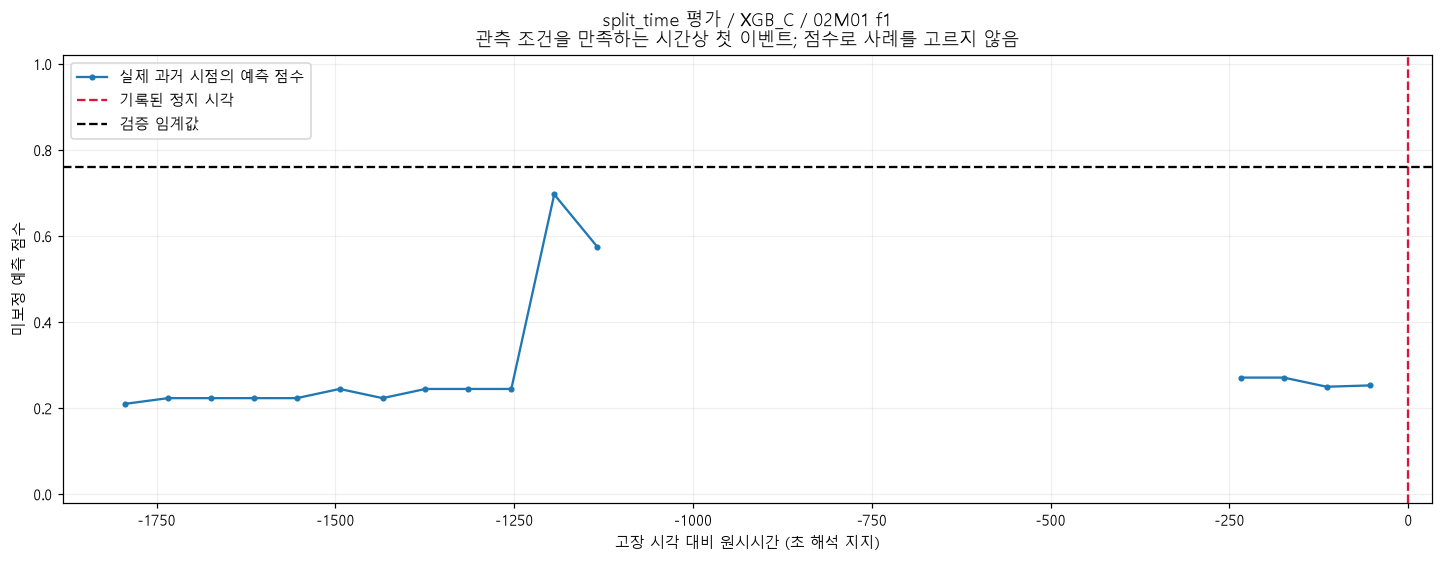

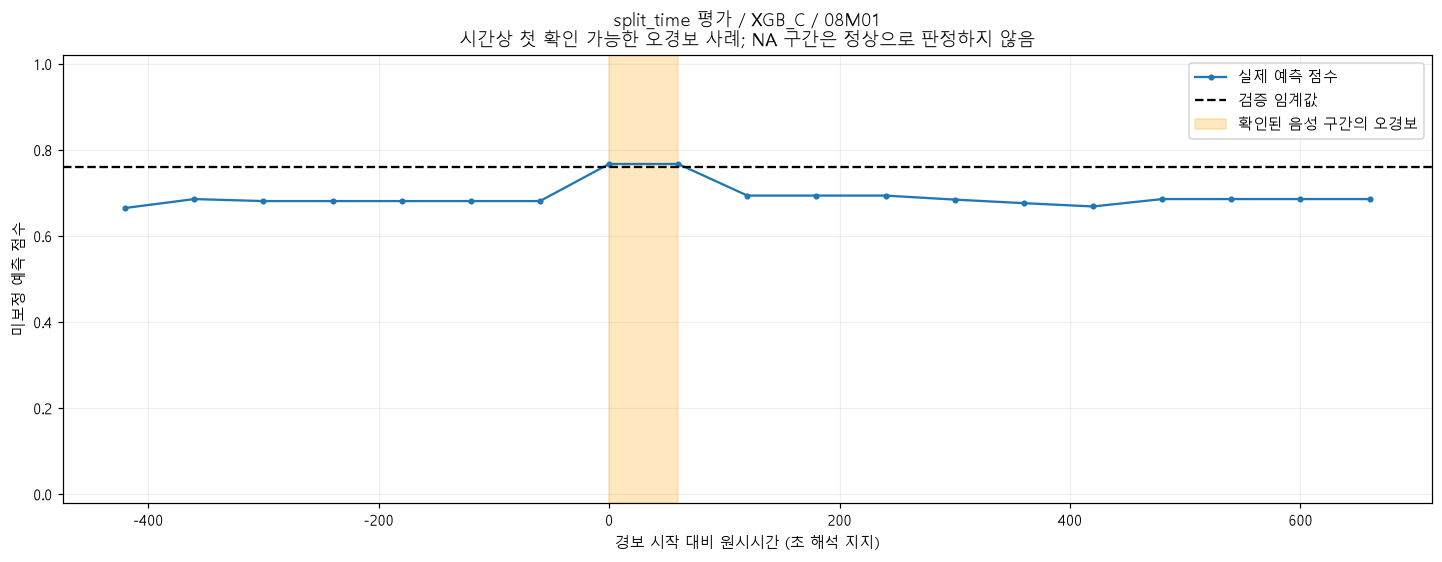

In [4]:
prospective=[read_json(OUT/"prospective"/s/"result.json") for s in ("split_tool","split_time")]
display(pd.DataFrame([{ "분할":r["scheme"],"RF/XGB 검증 선정":r["selected_name"],**{k:v for k,v in r["metrics"].items() if not isinstance(v,(dict,list))}} for r in prospective]))
display(Markdown("정답 미확인 구간에서 나온 경보는 확인된 오경보율의 분자에 넣을 수 없습니다. 다수의 미확인 경보가 존재하므로 현재 낮아 보이는 조건부 FAR만으로 현장 도입을 판단할 수 없습니다. 전체 이력 대비 도달률에는 관측/이력 부족도 반영됩니다."))
for scheme in ("split_tool","split_time"):plots.case_plots(scheme)

## 특징 중요도와 과적합

시간 순서로 선정한 실제 첫 사례에서 장비 평가 RF A의 점수는 낮은 수준으로 일정하고 임계값을 넘지 못했습니다. 시간 평가 XGBoost C의 점수는 앞쪽에서 일시적으로 높아졌지만 임계값보다 낮았으며, 마지막 600 구간에서도 경보가 발생하지 않았습니다. 두 사례에서 일관된 고장 직전 상승 패턴은 확인되지 않았습니다. 탐지 성공 사례를 골라 보여주지 않았으며, 이 미탐과 전체 이벤트 Recall을 함께 해석해야 합니다.

RF의 불순도 감소와 XGBoost gain은 다른 척도입니다. 공정 범주 수, 상관 특징 및 학습 분포에 영향을 받으므로 인과적 고장 원인으로 해석하지 않습니다. Tool/Lot/time/사용량은 별도 진단에만 있습니다. SHAP 상세 분석은 하지 않았습니다.

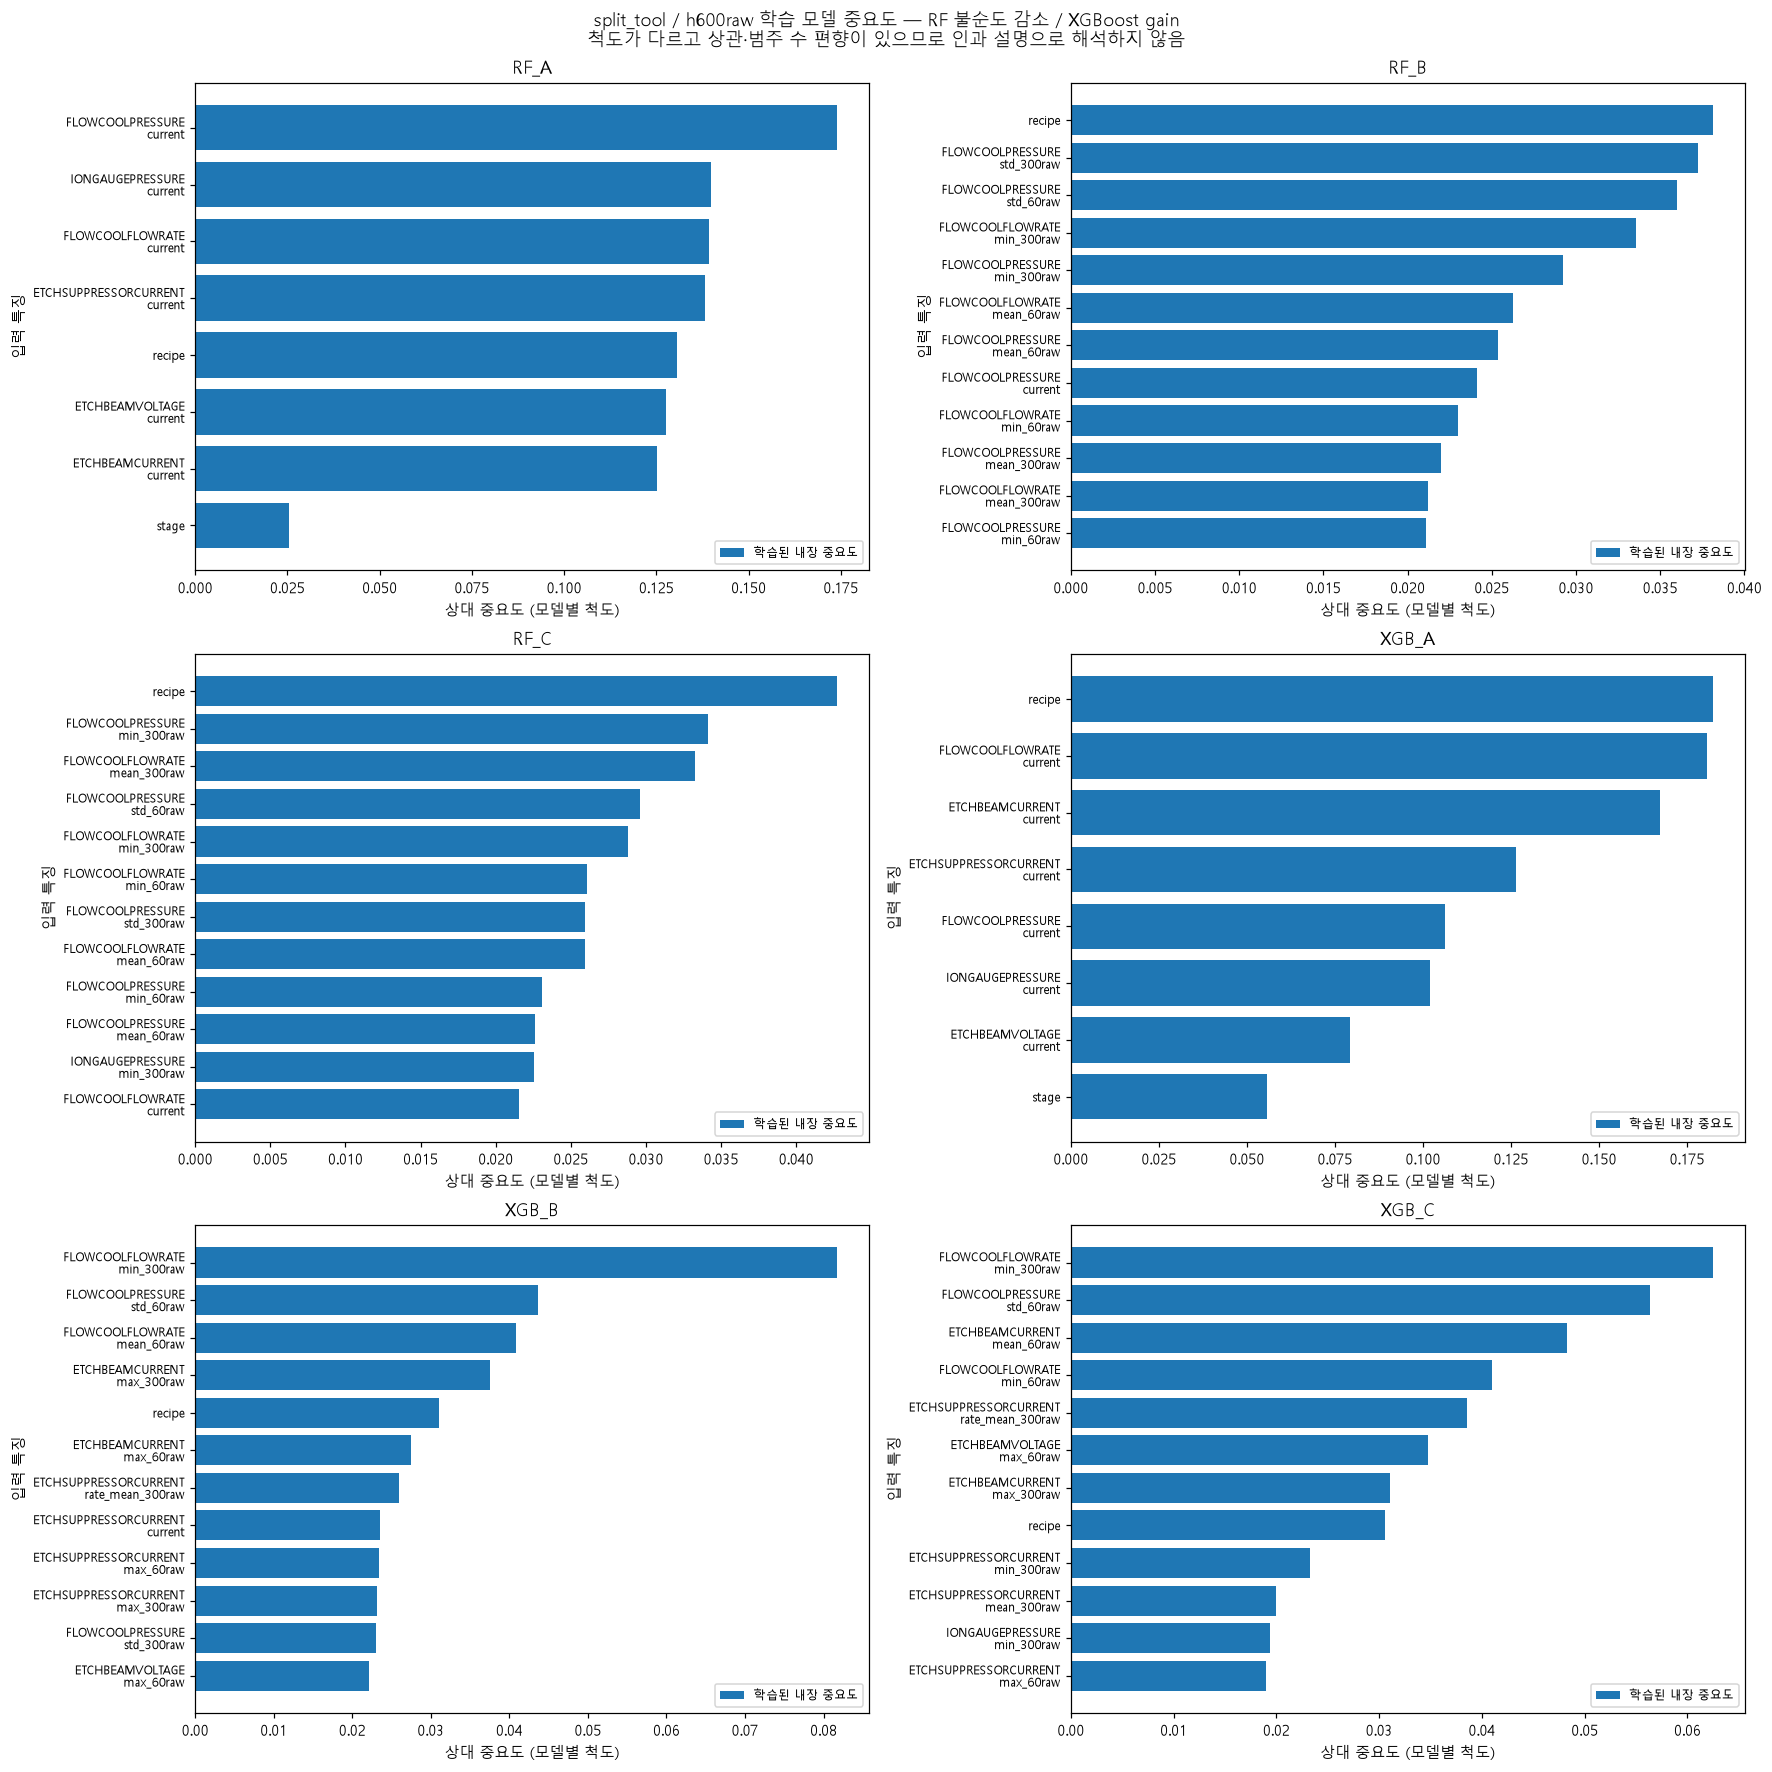

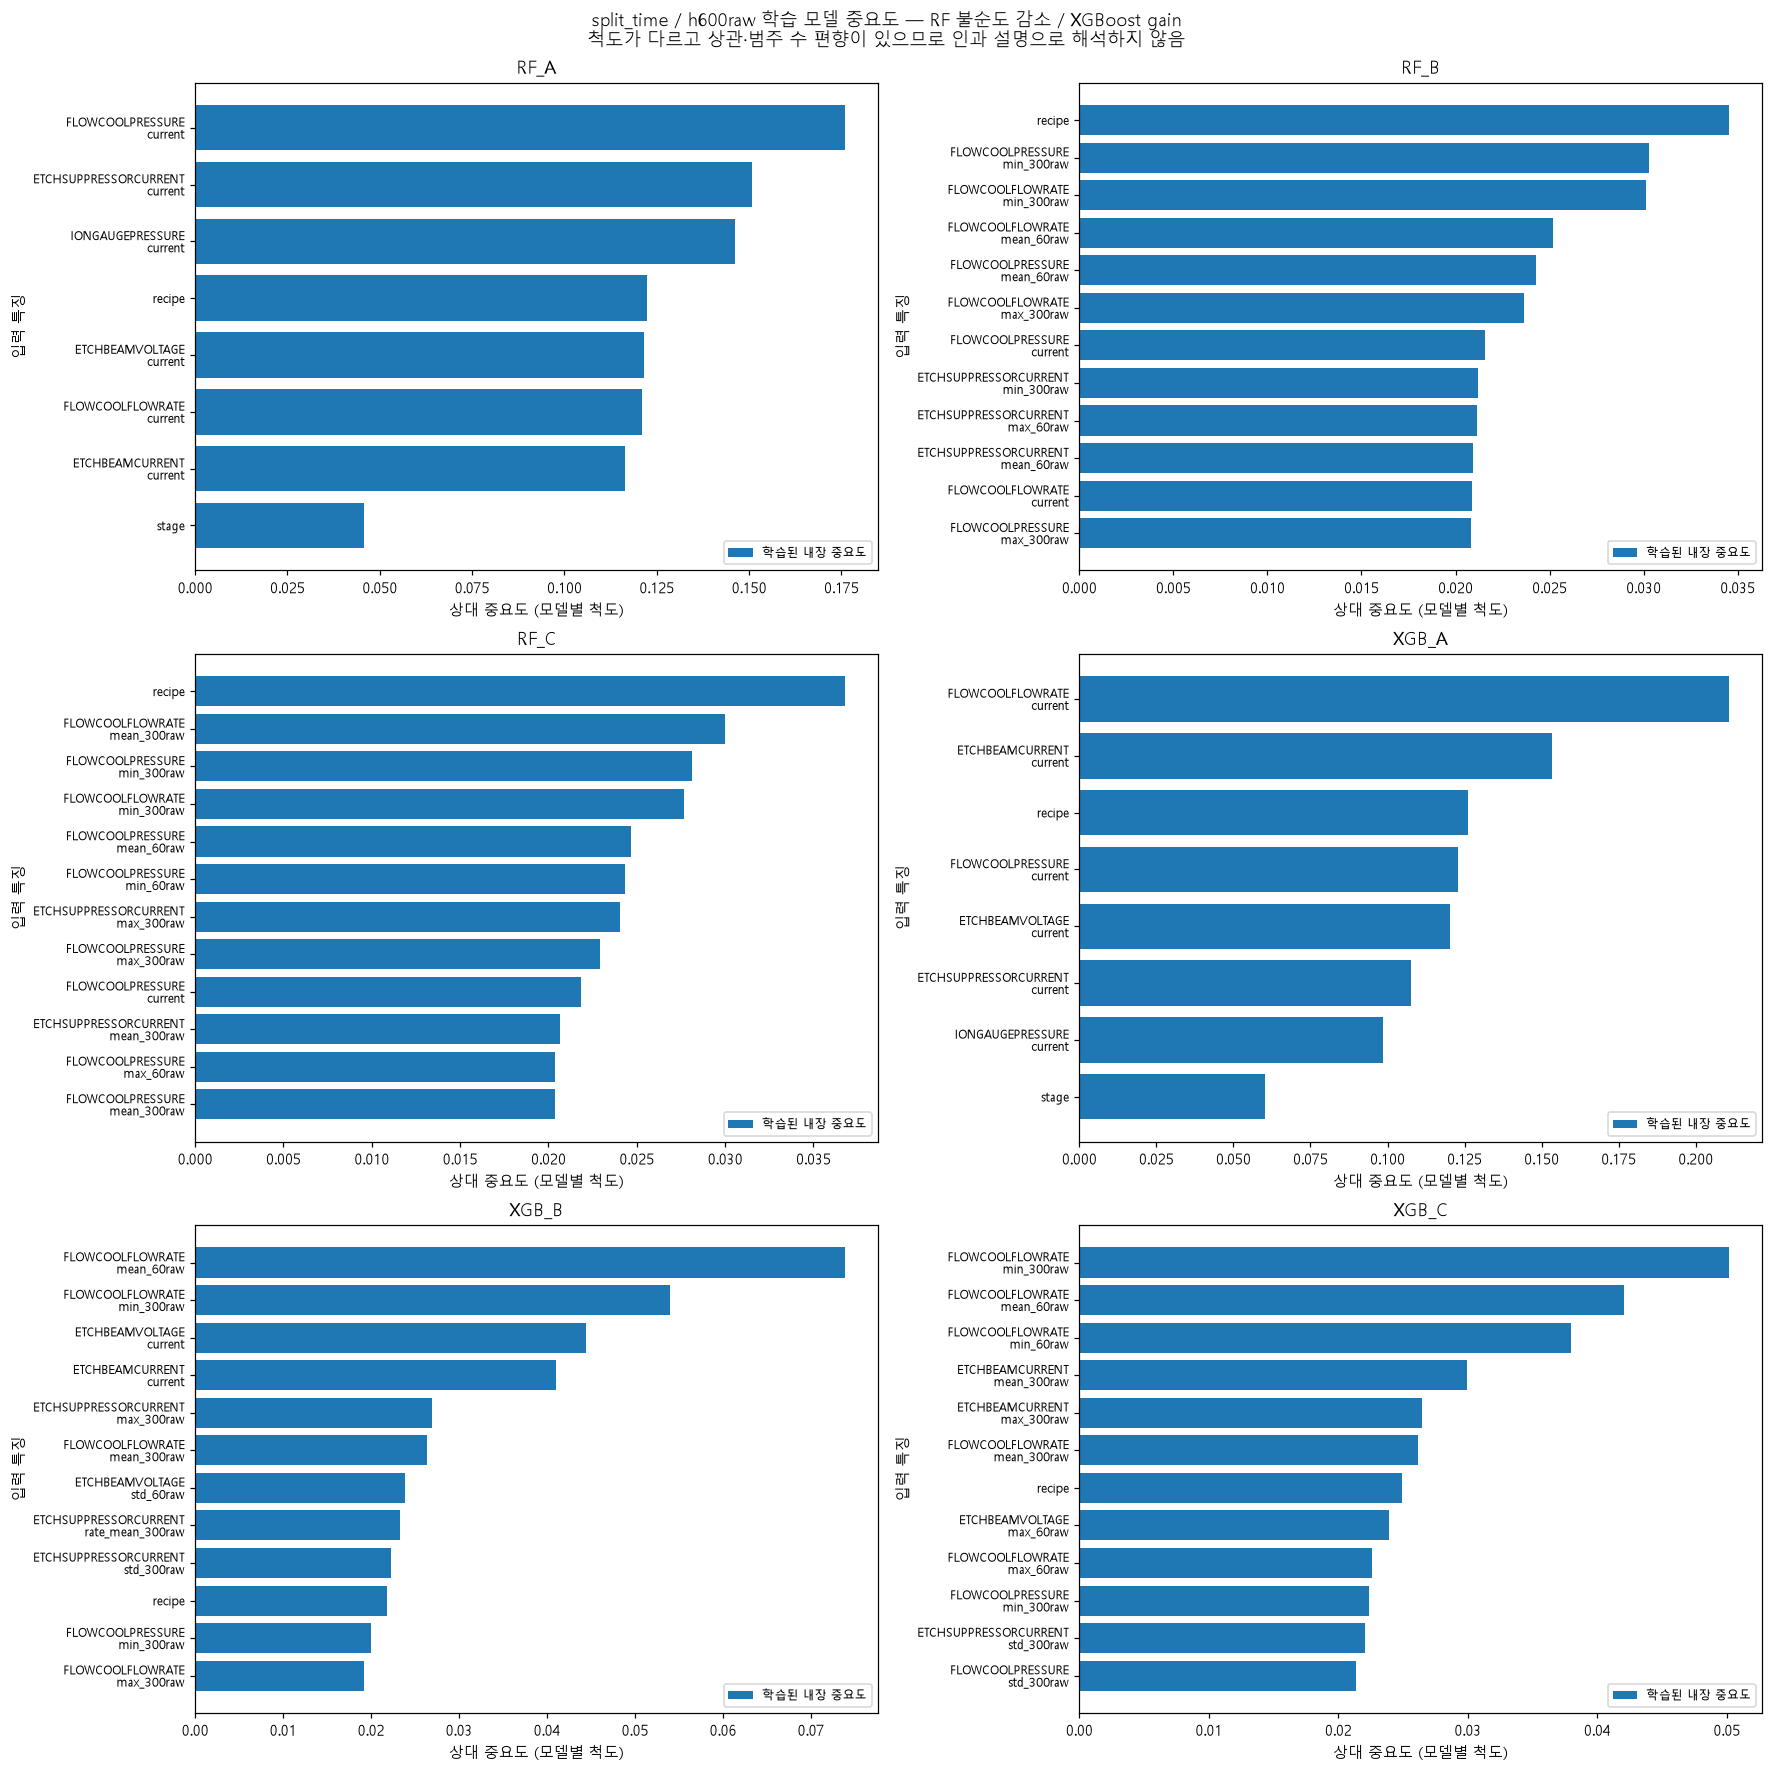

f1                       pr_auc_ap            \
split            evaluation     train validation evaluation     train   
scheme     name                                                         
split_time RF_A    0.203008  0.189047   0.043384   0.267084  0.224086   
           RF_B    0.215289  0.211735   0.087845   0.191183  0.413021   
           RF_C    0.171533  0.245395   0.080460   0.179330  0.400872   
           XGB_A   0.405360  0.033643   0.075559   0.315114  0.066300   
           XGB_B   0.303754  0.115536   0.143713   0.292510  0.061416   
           XGB_C   0.264758  0.139339   0.179245   0.278805  0.086625   
split_tool RF_A    0.098765  0.059803   0.067485   0.047113  0.343384   
           RF_B    0.000000  0.264687   0.026804   0.017619  0.452886   
           RF_C    0.054054  0.208309   0.026139   0.044049  0.445387   
           XGB_A   0.130081  0.098006   0.048309   0.085175  0.075170   
           XGB_B   0.026519  0.088173   0.036019   0.017211  0.140640   
           XGB_C   0.046630  0.082289   0.028725   0.015373  0.114648   

                             
split            validation  
scheme     name              
split_time RF_A    0.014738  
           RF_B    0.028168  
           RF_C    0.024293  
           XGB_A   0.035687  
           XGB_B   0.045612  
           XGB_C   0.050873  
split_tool RF_A    0.013677  
           RF_B    0.009096  
           RF_C    0.008842  
           XGB_A   0.011794  
           XGB_B   0.009680  
           XGB_C   0.009037

학습 AP와 검증/평가 AP의 큰 차이, 장비 분할과 시간 분할의 차이는 과적합과 분포 이동 가능성을 보여줍니다. 이는 누수가 없다는 검사 결과와 양립합니다. 83개 특징이 현재값 중심 구성보다 항상 좋은 것은 아닙니다. 다음 단계는 관측/라벨 검열 정책의 전향 검증, 장비 그룹 교차검증, 검증 분리와 확률 보정입니다.

In [5]:
for scheme in ("split_tool","split_time"):plots.importance(scheme)
comparison=metrics[(metrics.horizon==600)&(~metrics.identity_diagnostic)&metrics.name.str.startswith(("RF_","XGB_"))]
display(comparison.pivot_table(index=["scheme","name"],columns="split",values=["f1","pr_auc_ap"]))
display(Markdown("학습 AP와 검증/평가 AP의 큰 차이, 장비 분할과 시간 분할의 차이는 과적합과 분포 이동 가능성을 보여줍니다. 이는 누수가 없다는 검사 결과와 양립합니다. 83개 특징이 현재값 중심 구성보다 항상 좋은 것은 아닙니다. 다음 단계는 관측/라벨 검열 정책의 전향 검증, 장비 그룹 교차검증, 검증 분리와 확률 보정입니다."))

In [6]:
import unittest
suite=unittest.TestLoader().discover(str(ROOT/"tests"),pattern="test_models_phase4.py")
result=unittest.TextTestRunner(verbosity=2).run(suite)
assert result.wasSuccessful()
print("최종 검사:",read_json(OUT/"final_checks.json"))
display(Markdown("총 48개 주·확장 실험과 10개 식별자 진단 모델을 실제 실행했습니다. 모델·그래프·예측·설정은 outputs/stage4에 저장했습니다. 기존 원본·코드·Notebook·보고서는 보존했고 외부 업로드는 하지 않았습니다. LSTM·SHAP·현장 확률 보정·장비 교차검증은 미실행입니다."))

test_alarm_episodes_gap_rearm_and_state (test_models_phase4.ModelTests.test_alarm_episodes_gap_rearm_and_state) ... 

ok


test_features_exclude_target_and_identifiers (test_models_phase4.ModelTests.test_features_exclude_target_and_identifiers) ... 

ok


test_one_alarm_does_not_detect_two_sequential_events (test_models_phase4.ModelTests.test_one_alarm_does_not_detect_two_sequential_events) ... 

ok


... (3 outputs left out)

ok


----------------------------------------------------------------------
Ran 5 tests in 0.048s

OK


최종 검사: {'experiments': 58, 'core_experiments': 48, 'identity_experiments': 10, 'all_prediction_metrics_checked': True, 'prior_files_unchanged': True, 'prior_files_checked': 24, 'original_metadata_unchanged': True, 'features': {'A': 8, 'B': 80, 'C': 83}, 'passed': True}


총 48개 주·확장 실험과 10개 식별자 진단 모델을 실제 실행했습니다. 모델·그래프·예측·설정은 outputs/stage4에 저장했습니다. 기존 원본·코드·Notebook·보고서는 보존했고 외부 업로드는 하지 않았습니다. LSTM·SHAP·현장 확률 보정·장비 교차검증은 미실행입니다.